# 04. Эффективность каналов привлечения

**Цель.** Понять, какие каналы привлечения приводят самых ценных пользователей. В архиве нет AppsFlyer и Amplitude, поэтому используем то, что есть:
- **канал** = `secondary_category_filled` из таблицы привлечения;
- **поведение в приложении** (аналог Amplitude) = процессы пользователей: проверка личности, открытие карты, переводы, платежи, депозиты;
- **ценность** = транзакции и покупки у партнёров.

**Что важно знать об данных (проверено в аудите):**
- У многих клиентов в таблице привлечения **несколько разных каналов** (даты нет, определить «первый» канал нельзя).
- Есть полные дубли строк и пустые значения канала.
- Стоимости привлечения нет, поэтому оцениваем **качество** пользователей, а не окупаемость канала.
- Ценность это объём операций, а не доход компании.

**План.**
1. Чистим привлечение, считаем, у скольких клиентов несколько каналов.
2. Считаем метрики качества на клиента (активация, активность за 30 дней, покупки у партнёров, объём операций, шаги воронки).
3. Сравниваем каналы с доверительными интервалами.
4. Проверяем устойчивость к правилу атрибуции (один канал, любое касание, дробные веса).
5. Убираем эффект месяца регистрации (старые клиенты успели сделать больше операций).
6. Смотрим воронку по процессам приложения и объём против качества.
7. Считаем **время до первой операции** и находим, где клиенты застревают.
8. Строим **карту кросс-продаж**: какие партнёрские продукты чаще покупают клиенты каждого канала.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import duckdb
import matplotlib.pyplot as plt

PROJECT_ROOT = Path.cwd().parent
DATA_DIR = PROJECT_ROOT / "data" / "raw"

ACQ_FILE = DATA_DIR / "SAPP привлечения.csv"
TX_FILE = DATA_DIR / "SAPP транзакции.csv"
PP_FILE = DATA_DIR / "SAPP Покупки у партнеров.csv"
USERS_FILE = DATA_DIR / "SAPP пользователи.csv"
PROC_FILE = DATA_DIR / "SAPP Процессы пользователей в приложении.csv"

SUCCESS_STATUSES = ("Успешные", "AUSR0401", "AUSR0402")
MIN_CLIENTS = 1000            # каналы меньшего размера не интерпретируем
MIN_COHORT = 500              # минимальный размер канала в когортном анализе (раздел 8)
COHORT_DAYS = 30              # окно наблюдения после регистрации

# Группы партнёрских продуктов (как в 03_propensity)
PRODUCT_MAP = {
    "flights": "travel", "train_tickets": "travel", "tours": "travel", "Tours": "travel", "travel": "travel",
    "ticketon": "ticketon", "Тикетон": "ticketon",
    "groceries": "groceries", "fmedia": "fmedia",
    "telecom": "telecom", "ftelecom": "telecom", "Freedom Mobile": "telecom", "mobile": "telecom",
}
PROD_LIST = ["travel", "ticketon", "groceries", "fmedia", "telecom"]
PROCESS_START = "2026-01-01"  # период данных, как у транзакций

con = duckdb.connect()
con.execute("SET memory_limit = '2GB'")
con.execute("SET threads = 2")
print("OK:", all(p.exists() for p in [ACQ_FILE, TX_FILE, PP_FILE, USERS_FILE, PROC_FILE]))

OK: True


## 1. Привлечение: очистка и многоканальные клиенты

Удаляем строки без `customer_id` и полные дубли, пустой канал помечаем как `unknown` (это не то же самое, что `organic`).

In [2]:
con.execute(f"""
    CREATE OR REPLACE TABLE acq AS
    SELECT DISTINCT
        CAST(customer_id AS BIGINT) AS customer_id,
        COALESCE(secondary_category_filled, 'unknown') AS ch
    FROM read_csv_auto('{ACQ_FILE.as_posix()}')
    WHERE customer_id IS NOT NULL
""")

raw_rows = con.execute(f"SELECT COUNT(*) FROM read_csv_auto('{ACQ_FILE.as_posix()}')").fetchone()[0]
print(f"Строк в файле: {raw_rows:,}")
print(con.execute("SELECT COUNT(*) AS pairs, COUNT(DISTINCT customer_id) AS customers FROM acq").df())

per_cust = con.execute("""
    SELECT n_ch, COUNT(*) AS customers FROM (
        SELECT customer_id, COUNT(*) AS n_ch FROM acq GROUP BY customer_id)
    GROUP BY n_ch ORDER BY n_ch
""").df()
per_cust["share"] = (per_cust["customers"] / per_cust["customers"].sum()).round(3)
per_cust

Строк в файле: 1,119,512
    pairs  customers
0  950098     525207


,n_ch,customers,share
0,1,206952,0.394
1,2,211619,0.403
2,3,106636,0.203


## 2. Метрики качества на уровне клиента

Для каждого клиента считаем:
- `activated`: была хотя бы одна успешная транзакция;
- `active_last30`: была операция в последние 30 дней данных;
- `partner_buy`: была покупка у партнёров;
- `sum_amt`: суммарный объём успешных операций (выбросы обрезаны по 99,9-му процентилю);
- шаги воронки из процессов приложения (статус `COMPLETED`): проверка личности, открытие карты, переводы, платежи, депозит;
- `reg_month`: месяц регистрации (по самой ранней записи, в таблице пользователей id не уникален).

In [3]:
status_list = ", ".join(f"'{s}'" for s in SUCCESS_STATUSES)

con.execute(f"""
    CREATE OR REPLACE TABLE tx_raw AS
    SELECT CAST(customer_id AS BIGINT) AS customer_id,
           CAST(transaction_date AS DATE) AS d,
           ABS(CAST(transaction_sum AS DOUBLE)) AS amt
    FROM read_csv_auto('{TX_FILE.as_posix()}')
    WHERE transaction_status IN ({status_list}) AND customer_id IS NOT NULL
""")
cap = con.execute("SELECT quantile_cont(amt, 0.999) FROM tx_raw").fetchone()[0]
last_day = con.execute("SELECT MAX(d) FROM tx_raw").fetchone()[0]
con.execute(f"""
    CREATE OR REPLACE TABLE txc AS
    SELECT customer_id, COUNT(*) AS n_tx, SUM(LEAST(amt, {cap})) AS sum_amt, MAX(d) AS last_d
    FROM tx_raw GROUP BY customer_id
""")

con.execute(f"""
    CREATE OR REPLACE TABLE ppc AS
    SELECT CAST(customer_id AS BIGINT) AS customer_id, COUNT(*) AS n_pp
    FROM read_csv_auto('{PP_FILE.as_posix()}') WHERE customer_id IS NOT NULL GROUP BY 1
""")

con.execute(f"""
    CREATE OR REPLACE TABLE usr AS
    SELECT CAST(customer_id AS BIGINT) AS customer_id,
           MIN(CAST(reg_date AS DATE)) AS reg_date,
           strftime(MIN(CAST(reg_date AS DATE)), '%Y-%m') AS reg_month
    FROM read_csv_auto('{USERS_FILE.as_posix()}') GROUP BY 1
""")

con.execute(f"""
    CREATE OR REPLACE TABLE proc AS
    SELECT CAST(customer_id AS BIGINT) AS customer_id,
        MAX((process_code = 'LivenessProcess' AND status = 'COMPLETED')::INT)      AS liveness_ok,
        MAX((process_code = 'OpenCardProcess' AND status = 'COMPLETED')::INT)      AS card_opened,
        MAX((process_code IN ('P2pMoneyTransferProcessV2', 'DomesticMoneyTransferProcess',
             'ChildDomesticMoneyTransferProcess') AND status = 'COMPLETED')::INT)  AS transfer_ok,
        MAX((process_code IN ('PaymentProcess', 'PartnerPaymentProcess_V2',
             'AviataPaymentProcess_V2', 'ArbuzPaymentProcess_V2')
             AND status = 'COMPLETED')::INT)                                       AS payment_ok,
        MAX((process_code = 'OpenDepositProcess' AND status = 'COMPLETED')::INT)   AS deposit_opened
    FROM read_csv_auto('{PROC_FILE.as_posix()}')
    WHERE customer_id IS NOT NULL AND started_at >= TIMESTAMP '{PROCESS_START}'
    GROUP BY 1
""")

# Первая операция после регистрации и число операций в первые COHORT_DAYS дней
con.execute(f"""
    CREATE OR REPLACE TABLE txfirst AS
    SELECT t.customer_id,
           MIN(t.d) FILTER (WHERE t.d >= u.reg_date)                                     AS first_after,
           (MIN(t.d) < u.reg_date)::INT                                                  AS had_tx_before_reg,
           COUNT(*) FILTER (WHERE t.d >= u.reg_date AND t.d <= u.reg_date + {COHORT_DAYS}) AS n_tx_30
    FROM tx_raw t JOIN usr u USING (customer_id)
    GROUP BY t.customer_id, u.reg_date
""")

# Покупки у партнёров по группам продуктов
case_sql = "CASE app_name " + " ".join(f"WHEN '{k}' THEN '{v}'" for k, v in PRODUCT_MAP.items()) + " ELSE 'other' END"
flags_sql = ", ".join(f"MAX((prod = '{p}')::INT) AS bought_{p}" for p in PROD_LIST)
con.execute(f"""
    CREATE OR REPLACE TABLE ppf AS
    SELECT customer_id, {flags_sql}
    FROM (SELECT CAST(customer_id AS BIGINT) AS customer_id, {case_sql} AS prod
          FROM read_csv_auto('{PP_FILE.as_posix()}') WHERE customer_id IS NOT NULL)
    GROUP BY customer_id
""")
prod_select = ",\n        ".join(f"COALESCE(pf.bought_{p}, 0) AS bought_{p}" for p in PROD_LIST)

cv = con.execute(f"""
    SELECT a.customer_id, a.n_ch,
        COALESCE(t.n_tx, 0)                                  AS n_tx,
        COALESCE(t.sum_amt, 0)                               AS sum_amt,
        (t.n_tx IS NOT NULL)::INT                            AS activated,
        COALESCE((t.last_d > DATE '{last_day}' - 30)::INT, 0) AS active_last30,
        (p.n_pp IS NOT NULL)::INT                            AS partner_buy,
        COALESCE(pr.liveness_ok, 0)    AS liveness_ok,
        COALESCE(pr.card_opened, 0)    AS card_opened,
        COALESCE(pr.transfer_ok, 0)    AS transfer_ok,
        COALESCE(pr.payment_ok, 0)     AS payment_ok,
        COALESCE(pr.deposit_opened, 0) AS deposit_opened,
        u.reg_month, u.reg_date, tf.first_after,
        COALESCE(tf.had_tx_before_reg, 0) AS had_tx_before_reg,
        COALESCE(tf.n_tx_30, 0)           AS n_tx_30,
        {prod_select}
    FROM (SELECT customer_id, COUNT(*) AS n_ch FROM acq GROUP BY customer_id) a
    LEFT JOIN txc  t  USING (customer_id)
    LEFT JOIN ppc  p  USING (customer_id)
    LEFT JOIN proc pr USING (customer_id)
    LEFT JOIN usr  u  USING (customer_id)
    LEFT JOIN txfirst tf USING (customer_id)
    LEFT JOIN ppf pf USING (customer_id)
""").df()

print(f"Клиентов: {len(cv):,} | последний день данных: {last_day}")
print("Без месяца регистрации:", cv["reg_month"].isna().mean().round(4))
cv[["activated", "active_last30", "partner_buy", "liveness_ok", "card_opened",
    "transfer_ok", "payment_ok", "deposit_opened"]].mean().round(3)

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

FloatProgress(value=0.0, layout=Layout(width='auto'), style=ProgressStyle(bar_color='black'))

Клиентов: 525,207 | последний день данных: 2026-05-12
Без месяца регистрации: 0.0036


activated         0.439
active_last30     0.272
partner_buy       0.186
liveness_ok       0.870
card_opened       0.843
transfer_ok       0.575
payment_ok        0.311
deposit_opened    0.039
dtype: float64

## 3. Сравнение каналов (клиенты ровно с одним каналом)

Самый «чистый» вариант: клиенту можно однозначно приписать канал. Для долей считаем доверительный интервал Уилсона (95%).

In [4]:
acq = con.execute("SELECT * FROM acq").df()
pairs = acq.merge(cv, on="customer_id")
pairs["w_any"] = 1.0
pairs["w_frac"] = 1.0 / pairs["n_ch"]

METRICS = ["activated", "active_last30", "partner_buy"]

def wilson(k, n, z=1.96):
    if n == 0:
        return (np.nan, np.nan)
    p = k / n
    den = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / den
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / den
    return centre - half, centre + half

single = pairs[pairs["n_ch"] == 1]
rows = []
for ch, g in single.groupby("ch"):
    n = len(g)
    if n < MIN_CLIENTS:
        continue
    row = {"Канал": ch, "Клиентов": n}
    for m in METRICS:
        lo, hi = wilson(g[m].sum(), n)
        row[m] = g[m].mean()
        row[m + "_lo"], row[m + "_hi"] = lo, hi
    row["Объём на активированного, тг"] = g.loc[g.activated == 1, "sum_amt"].mean()
    row["Активных за 30 дн., чел."] = int(g["active_last30"].sum())
    rows.append(row)

res = pd.DataFrame(rows).set_index("Канал").sort_values("activated", ascending=False)
overall = single[METRICS].mean()
print("Средние по всем клиентам с одним каналом:")
print(overall.round(3).to_string())
res[["Клиентов", "activated", "active_last30", "partner_buy",
     "Объём на активированного, тг", "Активных за 30 дн., чел."]].round(3)

Средние по всем клиентам с одним каналом:
activated        0.297
active_last30    0.175
partner_buy      0.127


,Клиентов,activated,active_last30,partner_buy,"Объём на активированного, тг","Активных за 30 дн., чел."
Канал,,,,,,
bank,16802,0.385,0.218,0.171,1734014.256,3656
organic,80975,0.356,0.220,0.153,2559446.078,17836
FMedia,1649,0.305,0.133,0.203,1031763.606,220
Arbuz,7618,0.268,0.159,0.097,2189033.611,1212
unknown,57821,0.251,0.141,0.112,2495600.006,8125
FTravel,14057,0.234,0.133,0.092,1703900.225,1864
Insurance,1391,0.215,0.101,0.054,883917.718,141
Ticketon,22456,0.212,0.118,0.078,1438088.888,2647
FDrive,1170,0.204,0.150,0.083,875732.891,176


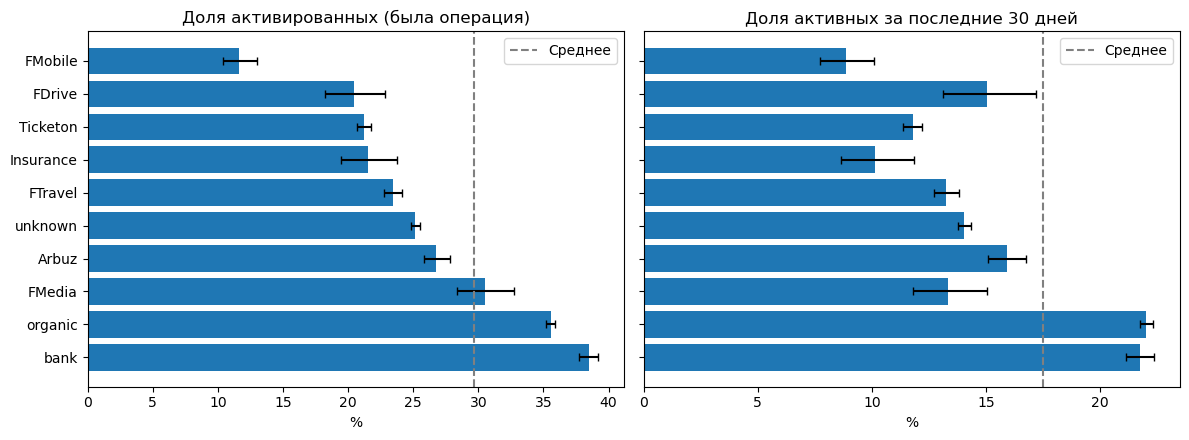

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
order = res.index
for ax, m, title in zip(axes, ["activated", "active_last30"],
                        ["Доля активированных (была операция)", "Доля активных за последние 30 дней"]):
    vals = res.loc[order, m].values
    err = [vals - res.loc[order, m + "_lo"].values, res.loc[order, m + "_hi"].values - vals]
    ax.barh(order, vals * 100, xerr=np.array(err) * 100, capsize=3)
    ax.axvline(overall[m] * 100, linestyle="--", color="gray", label="Среднее")
    ax.set_title(title)
    ax.set_xlabel("%")
    ax.invert_yaxis()
    ax.legend()
plt.tight_layout()
plt.show()

## 4. Устойчивость к правилу атрибуции

У 60% и более клиентов несколько каналов, и мы не знаем, какой из них «настоящий». Считаем метрику тремя способами:
- **один канал**: только клиенты ровно с одним каналом;
- **любое касание**: клиент учитывается в каждом своём канале;
- **дробная атрибуция**: клиент делится поровну между своими каналами (вес 1/k).

Если ранжирование каналов похоже во всех трёх вариантах, выводам можно доверять.

In [6]:
def weighted_rate(df, wcol, metric):
    return (df[metric] * df[wcol]).groupby(df["ch"]).sum() / df[wcol].groupby(df["ch"]).sum()

big = res.index
comp = {}
for m in ["activated", "active_last30"]:
    comp[(m, "один канал")] = weighted_rate(single.assign(w=1.0), "w", m)
    comp[(m, "любое касание")] = weighted_rate(pairs, "w_any", m)
    comp[(m, "дробная")] = weighted_rate(pairs, "w_frac", m)
comp = pd.DataFrame(comp).loc[big]
comp.columns = [f"{a} | {b}" for a, b in comp.columns]
comp.round(3)

,activated | один канал,activated | любое касание,activated | дробная,active_last30 | один канал,active_last30 | любое касание,active_last30 | дробная
Канал,,,,,,
bank,0.385,0.566,0.534,0.218,0.355,0.330
organic,0.356,0.492,0.455,0.220,0.312,0.287
FMedia,0.305,0.554,0.511,0.133,0.305,0.273
Arbuz,0.268,0.507,0.469,0.159,0.325,0.298
unknown,0.251,0.423,0.365,0.141,0.257,0.217
FTravel,0.234,0.505,0.453,0.133,0.309,0.274
Insurance,0.215,0.481,0.433,0.101,0.298,0.263
Ticketon,0.212,0.464,0.411,0.118,0.286,0.250
FDrive,0.204,0.450,0.412,0.150,0.327,0.299


In [7]:
act = comp[[c for c in comp.columns if c.startswith("activated")]]
print("Корреляция рангов каналов по активации (Спирмен):")
print(act.rank().corr(method="spearman").round(2))
print()
print("Ранг канала (1 = лучший) по активации:")
act.rank(ascending=False).astype(int)

Корреляция рангов каналов по активации (Спирмен):
                           activated | один канал  activated | любое касание  \
activated | один канал                       1.00                       0.79   
activated | любое касание                    0.79                       1.00   
activated | дробная                          0.83                       0.98   

                           activated | дробная  
activated | один канал                    0.83  
activated | любое касание                 0.98  
activated | дробная                       1.00  

Ранг канала (1 = лучший) по активации:


,activated | один канал,activated | любое касание,activated | дробная
Канал,,,
bank,1,1,1
organic,2,5,4
FMedia,3,2,2
Arbuz,4,3,3
unknown,5,9,9
FTravel,6,4,5
Insurance,7,6,6
Ticketon,8,7,8
FDrive,9,8,7


## 5. Поправка на месяц регистрации

Клиент, пришедший в январе, успел сделать больше, чем пришедший в мае. Если у каналов разный состав по месяцам, сравнение нечестное. Приводим все каналы к одному составу месяцев (прямая стандартизация): считаем долю активированных внутри каждого месяца и усредняем с одинаковыми весами месяцев.

In [8]:
s = single.dropna(subset=["reg_month"])
month_w = s["reg_month"].value_counts(normalize=True)

def standardized(g, metric, min_cell=30):
    by_m = g.groupby("reg_month")[metric].agg(["mean", "size"])
    by_m = by_m[by_m["size"] >= min_cell]
    w = month_w.reindex(by_m.index)
    return (by_m["mean"] * w).sum() / w.sum()

adj = pd.DataFrame({
    "Сырая активация": res["activated"],
    "С поправкой на месяц": [standardized(s[s["ch"] == ch], "activated") for ch in res.index],
}, index=res.index)
adj["Разница"] = adj["С поправкой на месяц"] - adj["Сырая активация"]

mix = (s[s["ch"].isin(res.index)].groupby(["ch", "reg_month"]).size()
         .unstack(fill_value=0))
mix = mix.div(mix.sum(axis=1), axis=0)
print("Состав клиентов канала по месяцам регистрации (доли):")
print(mix.round(2).to_string())
print()
adj.sort_values("С поправкой на месяц", ascending=False).round(3)

Состав клиентов канала по месяцам регистрации (доли):
reg_month  2026-01  2026-02  2026-03  2026-04  2026-05
ch                                                    
Arbuz         0.30     0.25     0.18     0.20     0.06
FDrive        0.01     0.07     0.30     0.53     0.10
FMedia        0.25     0.25     0.28     0.20     0.03
FMobile       0.23     0.09     0.10     0.47     0.11
FTravel       0.39     0.28     0.18     0.12     0.03
Insurance     0.10     0.20     0.31     0.34     0.06
Ticketon      0.31     0.21     0.24     0.18     0.05
bank          0.29     0.26     0.25     0.15     0.05
organic       0.34     0.23     0.19     0.19     0.05
unknown       0.47     0.22     0.16     0.12     0.03



,Сырая активация,С поправкой на месяц,Разница
Канал,,,
bank,0.385,0.393,0.008
organic,0.356,0.358,0.002
FMedia,0.305,0.311,0.006
Arbuz,0.268,0.276,0.008
Insurance,0.215,0.256,0.041
unknown,0.251,0.244,-0.008
FTravel,0.234,0.233,-0.001
Ticketon,0.212,0.214,0.002
FDrive,0.204,0.188,-0.017


## 6. Воронка по процессам приложения

Какая доля клиентов канала прошла ключевые шаги (завершённые процессы): проверку личности, открытие карты, перевод, платёж, открытие депозита.

In [9]:
FUNNEL = ["liveness_ok", "card_opened", "transfer_ok", "payment_ok", "deposit_opened"]
fun = single[single["ch"].isin(res.index)].groupby("ch")[FUNNEL].mean().loc[res.index]
fun.loc["ВСЕ (среднее)"] = single[FUNNEL].mean()
fun.columns = ["Проверка личности", "Открыта карта", "Перевод", "Платёж", "Депозит"]
fun.round(3)

,Проверка личности,Открыта карта,Перевод,Платёж,Депозит
Канал,,,,,
bank,0.949,0.890,0.318,0.267,0.019
organic,0.771,0.728,0.534,0.253,0.035
FMedia,0.890,0.809,0.273,0.247,0.012
Arbuz,0.773,0.702,0.388,0.169,0.024
unknown,0.668,0.621,0.486,0.178,0.018
FTravel,0.645,0.595,0.488,0.159,0.016
Insurance,0.896,0.791,0.220,0.096,0.008
Ticketon,0.632,0.591,0.484,0.144,0.013
FDrive,0.773,0.698,0.326,0.136,0.014


## 7. Объём против качества

Один канал может приводить много клиентов низкого качества, другой мало, но хороших. Смотрим, сколько **активных** пользователей даёт каждый канал и какова их доля.

In [10]:
vq = res[["Клиентов", "activated", "active_last30", "Активных за 30 дн., чел."]].copy()
vq["Доля от всех активных"] = vq["Активных за 30 дн., чел."] / vq["Активных за 30 дн., чел."].sum()
vq["Доля от всех клиентов"] = vq["Клиентов"] / vq["Клиентов"].sum()
vq["Качество к среднему"] = vq["active_last30"] / overall["active_last30"]
vq.sort_values("Активных за 30 дн., чел.", ascending=False).round(3)

,Клиентов,activated,active_last30,"Активных за 30 дн., чел.",Доля от всех активных,Доля от всех клиентов,Качество к среднему
Канал,,,,,,,
organic,80975,0.356,0.220,17836,0.494,0.393,1.259
unknown,57821,0.251,0.141,8125,0.225,0.280,0.803
bank,16802,0.385,0.218,3656,0.101,0.081,1.243
Ticketon,22456,0.212,0.118,2647,0.073,0.109,0.674
FTravel,14057,0.234,0.133,1864,0.052,0.068,0.758
Arbuz,7618,0.268,0.159,1212,0.034,0.037,0.909
FMedia,1649,0.305,0.133,220,0.006,0.008,0.762
FMobile,2272,0.116,0.088,201,0.006,0.011,0.506
FDrive,1170,0.204,0.150,176,0.005,0.006,0.860


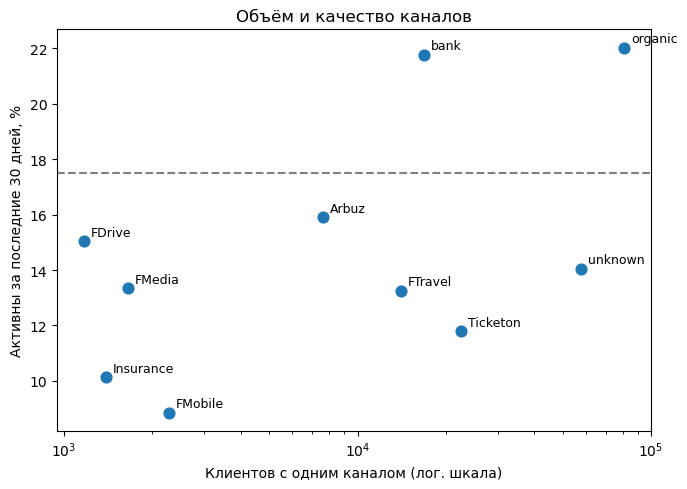

In [11]:
fig, ax = plt.subplots(figsize=(7, 5))
ax.scatter(vq["Клиентов"], vq["active_last30"] * 100, s=60)
for ch, r in vq.iterrows():
    ax.annotate(ch, (r["Клиентов"], r["active_last30"] * 100), textcoords="offset points",
                xytext=(5, 4), fontsize=9)
ax.axhline(overall["active_last30"] * 100, linestyle="--", color="gray")
ax.set_xscale("log")
ax.set_xlabel("Клиентов с одним каналом (лог. шкала)")
ax.set_ylabel("Активны за последние 30 дней, %")
ax.set_title("Объём и качество каналов")
plt.tight_layout()
plt.show()

## 8. Время до первой операции и точка застревания

Для каждого канала смотрим, **как быстро** клиент делает первую успешную операцию после регистрации, и строим строгую воронку: клиент учитывается на шаге, только если прошёл все предыдущие.

Правила когорты:
- только клиенты с одним каналом и известной датой регистрации;
- регистрация не позже чем за `COHORT_DAYS` дней до конца данных (у всех одинаковое окно наблюдения);
- клиентов с операциями **до** даты регистрации исключаем (признак склейки разных людей под одним `customer_id`);
- дата регистрации берётся по самой ранней записи, и это допущение (в таблице пользователей id не уникален);
- шаги «проверка личности» и «карта» взяты из процессов приложения за весь 2026 год, без привязки к окну.

In [12]:
cohort = cv[cv["n_ch"] == 1].merge(acq, on="customer_id").dropna(subset=["reg_date"]).copy()
cohort["reg_date"] = pd.to_datetime(cohort["reg_date"])
cohort["first_after"] = pd.to_datetime(cohort["first_after"])

n0 = len(cohort)
too_late = cohort["reg_date"] > pd.Timestamp(last_day) - pd.Timedelta(days=COHORT_DAYS)
cohort = cohort[~too_late]
n1 = len(cohort)
anomaly = cohort["had_tx_before_reg"] == 1
cohort = cohort[~anomaly].copy()
print(f"Клиентов с одним каналом и датой регистрации: {n0:,}")
print(f"  исключено (зарегистрировались менее чем за {COHORT_DAYS} дней до конца данных): {n0 - n1:,}")
print(f"  исключено (есть операции до даты регистрации): {int(anomaly.sum()):,} ({anomaly.mean():.1%})")
print(f"В когорте: {len(cohort):,}")

cohort["days_to_first"] = (cohort["first_after"] - cohort["reg_date"]).dt.days
sizes = cohort["ch"].value_counts()
cohort_channels = sizes[sizes >= MIN_COHORT].index
print("Каналы в когорте:", ", ".join(f"{c} ({sizes[c]:,})" for c in cohort_channels))

Клиентов с одним каналом и датой регистрации: 206,293
  исключено (зарегистрировались менее чем за 30 дней до конца данных): 28,963
  исключено (есть операции до даты регистрации): 1,381 (0.8%)
В когорте: 175,949
Каналы в когорте: organic (67,104), unknown (52,041), Ticketon (18,944), bank (14,295), FTravel (12,681), Arbuz (6,176), FMedia (1,386), FMobile (1,121), Insurance (1,018), FDrive (795)


In [13]:
DAYS = [0, 1, 3, 7, 14, 30]
cc = cohort[cohort["ch"].isin(cohort_channels)]

curve = pd.DataFrame({
    f"за {d} дн." if d else "в день регистрации": cc.groupby("ch")["days_to_first"].apply(lambda s: (s <= d).mean())
    for d in DAYS
}).loc[cohort_channels]
curve.insert(0, "Клиентов", sizes[cohort_channels])
overall_curve = pd.Series({k: (cc["days_to_first"] <= d).mean() for k, d in zip(curve.columns[1:], DAYS)})
print("Доля клиентов, сделавших первую успешную операцию в течение N дней после регистрации")
curve.sort_values("за 30 дн.", ascending=False).round(3)

Доля клиентов, сделавших первую успешную операцию в течение N дней после регистрации


,Клиентов,в день регистрации,за 1 дн.,за 3 дн.,за 7 дн.,за 14 дн.,за 30 дн.
ch,,,,,,,
bank,14295,0.147,0.178,0.205,0.234,0.264,0.312
organic,67104,0.134,0.168,0.194,0.222,0.251,0.295
FMedia,1386,0.146,0.175,0.190,0.210,0.227,0.253
Arbuz,6176,0.095,0.115,0.137,0.158,0.185,0.222
Insurance,1018,0.110,0.130,0.148,0.166,0.176,0.202
FDrive,795,0.074,0.101,0.113,0.131,0.150,0.191
unknown,52041,0.076,0.096,0.112,0.130,0.149,0.183
FTravel,12681,0.075,0.095,0.108,0.125,0.144,0.175
Ticketon,18944,0.073,0.092,0.106,0.122,0.141,0.171


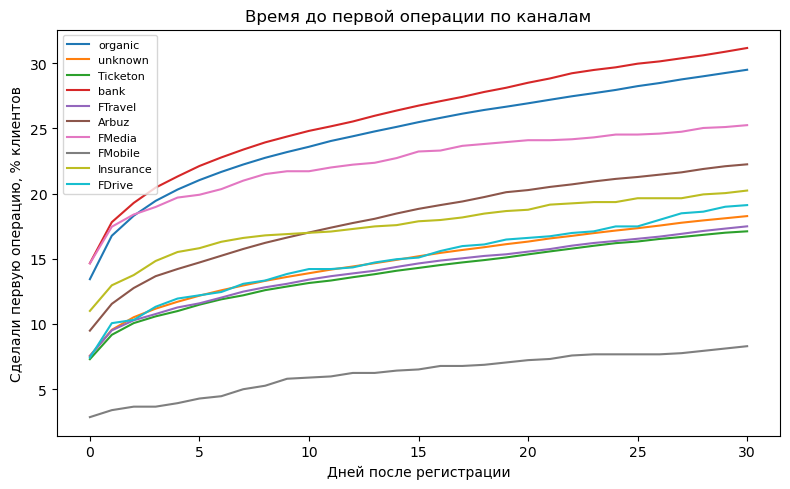

In [14]:
fig, ax = plt.subplots(figsize=(8, 5))
grid = range(0, COHORT_DAYS + 1)
for ch in cohort_channels:
    s = cc[cc["ch"] == ch]["days_to_first"]
    ax.plot(list(grid), [(s <= d).mean() * 100 for d in grid], label=ch)
ax.set_xlabel("Дней после регистрации")
ax.set_ylabel("Сделали первую операцию, % клиентов")
ax.set_title("Время до первой операции по каналам")
ax.legend(fontsize=8)
plt.tight_layout()
plt.show()

In [15]:
c = cc.copy()
c["s_live"] = c["liveness_ok"]
c["s_card"] = c["s_live"] * c["card_opened"]
c["s_first"] = c["s_card"] * (c["days_to_first"] <= COHORT_DAYS).astype(int)
c["s_repeat"] = c["s_first"] * (c["n_tx_30"] >= 2).astype(int)

steps = ["s_live", "s_card", "s_first", "s_repeat"]
names = ["Проверка личности", "Открыта карта", "Первая операция (30 дн.)", "Повторная операция"]
cum = c.groupby("ch")[steps].mean().loc[cohort_channels]
cum.loc["ВСЕ"] = c[steps].mean()
cum.columns = names

step_rate = pd.DataFrame(index=cum.index)
prev = pd.Series(1.0, index=cum.index)
for col in names:
    step_rate[col] = cum[col] / prev
    prev = cum[col]

leak = step_rate.idxmin(axis=1).rename("Главная потеря на шаге")
print("Накопительная воронка (доля от всех клиентов канала):")
display(cum.round(3))
print("Конверсия шаг к шагу (какая доля прошла от предыдущего шага):")
display(step_rate.round(3).join(leak))

Накопительная воронка (доля от всех клиентов канала):


,Проверка личности,Открыта карта,Первая операция (30 дн.),Повторная операция
ch,,,,
organic,0.747,0.706,0.289,0.210
unknown,0.656,0.613,0.178,0.120
Ticketon,0.610,0.571,0.167,0.109
bank,0.948,0.892,0.307,0.202
FTravel,0.624,0.577,0.168,0.112
Arbuz,0.754,0.686,0.215,0.153
FMedia,0.882,0.806,0.240,0.124
FMobile,0.987,0.873,0.079,0.050
Insurance,0.891,0.780,0.189,0.092


Конверсия шаг к шагу (какая доля прошла от предыдущего шага):


,Проверка личности,Открыта карта,Первая операция (30 дн.),Повторная операция,Главная потеря на шаге
ch,,,,,
organic,0.747,0.945,0.409,0.727,Первая операция (30 дн.)
unknown,0.656,0.935,0.291,0.671,Первая операция (30 дн.)
Ticketon,0.610,0.937,0.292,0.652,Первая операция (30 дн.)
bank,0.948,0.940,0.344,0.658,Первая операция (30 дн.)
FTravel,0.624,0.924,0.292,0.667,Первая операция (30 дн.)
Arbuz,0.754,0.909,0.313,0.712,Первая операция (30 дн.)
FMedia,0.882,0.914,0.298,0.517,Первая операция (30 дн.)
FMobile,0.987,0.885,0.091,0.629,Первая операция (30 дн.)
Insurance,0.891,0.875,0.242,0.490,Первая операция (30 дн.)


In [16]:
c["stuck_card"] = ((c["card_opened"] == 1) & ~(c["days_to_first"] <= COHORT_DAYS)).astype(int)
stuck = c.groupby("ch").agg(clients=("stuck_card", "size"), stuck=("stuck_card", "sum")).loc[cohort_channels]
stuck["Доля застрявших"] = stuck["stuck"] / stuck["clients"]
stuck.columns = ["Клиентов", "Карта есть, операций нет", "Доля застрявших"]
print(f"Всего «застрявших»: {int(c['stuck_card'].sum()):,} из {len(c):,} ({c['stuck_card'].mean():.1%})")
stuck.sort_values("Карта есть, операций нет", ascending=False).round(3)

Всего «застрявших»: 77,402 из 175,561 (44.1%)


,Клиентов,"Карта есть, операций нет",Доля застрявших
ch,,,
organic,67104,27990,0.417
unknown,52041,22646,0.435
bank,14295,8360,0.585
Ticketon,18944,7669,0.405
FTravel,12681,5182,0.409
Arbuz,6176,2910,0.471
FMobile,1121,890,0.794
FMedia,1386,784,0.566
Insurance,1018,602,0.591


**Как читать.** «Застрявшие» это клиенты, которые открыли карту, но за 30 дней после регистрации не сделали ни одной успешной операции. Это готовая аудитория для кампании активации (например, бонус за первую покупку), и её размер по каналам показывает, где такая кампания даст больше всего.

## 9. Карта кросс-продаж по каналам

Какая доля клиентов каждого канала покупала партнёрские продукты и во сколько раз это чаще или реже среднего (lift). Клетки, где покупателей меньше 30, помечаем как ненадёжные. Пары «канал → его собственный продукт» (например, пришёл через Ticketon и купил Ticketon) тривиальны, поэтому в ранжировании «неочевидных» связок исключаем их. Соответствие каналов продуктам это **допущение по названиям**.

In [17]:
flags = [f"bought_{p}" for p in PROD_LIST]
sc = single[single["ch"].isin(res.index)]
rates = sc.groupby("ch")[flags].mean().loc[res.index]
buyers = sc.groupby("ch")[flags].sum().loc[res.index]
overall_rates = single[flags].mean()
lift_map = rates / overall_rates
rates.columns = lift_map.columns = buyers.columns = PROD_LIST

print("Средняя доля покупателей продукта по всем клиентам с одним каналом:")
print(overall_rates.set_axis(PROD_LIST).round(3).to_string())
print()
print("Доля клиентов канала, купивших продукт:")
display(rates.round(3))
print("Lift относительно среднего (больше 1 — покупают чаще среднего):")
display(lift_map.round(2))

Средняя доля покупателей продукта по всем клиентам с одним каналом:
travel       0.058
ticketon     0.059
groceries    0.017
fmedia       0.013
telecom      0.005

Доля клиентов канала, купивших продукт:


,travel,ticketon,groceries,fmedia,telecom
Канал,,,,,
bank,0.051,0.113,0.023,0.009,0.003
organic,0.075,0.066,0.022,0.014,0.007
FMedia,0.054,0.049,0.010,0.115,0.002
Arbuz,0.040,0.041,0.023,0.008,0.002
unknown,0.050,0.052,0.016,0.014,0.003
FTravel,0.060,0.028,0.007,0.007,0.005
Insurance,0.021,0.027,0.003,0.006,0.002
Ticketon,0.030,0.040,0.006,0.009,0.003
FDrive,0.053,0.023,0.007,0.005,0.002


Lift относительно среднего (больше 1 — покупают чаще среднего):


,travel,ticketon,groceries,fmedia,telecom
Канал,,,,,
bank,0.88,1.93,1.36,0.71,0.67
organic,1.30,1.13,1.28,1.08,1.49
FMedia,0.94,0.84,0.61,8.76,0.40
Arbuz,0.70,0.70,1.37,0.59,0.43
unknown,0.87,0.89,0.95,1.09,0.71
FTravel,1.04,0.47,0.39,0.55,1.10
Insurance,0.36,0.47,0.17,0.44,0.47
Ticketon,0.53,0.69,0.33,0.68,0.57
FDrive,0.92,0.39,0.40,0.39,0.37


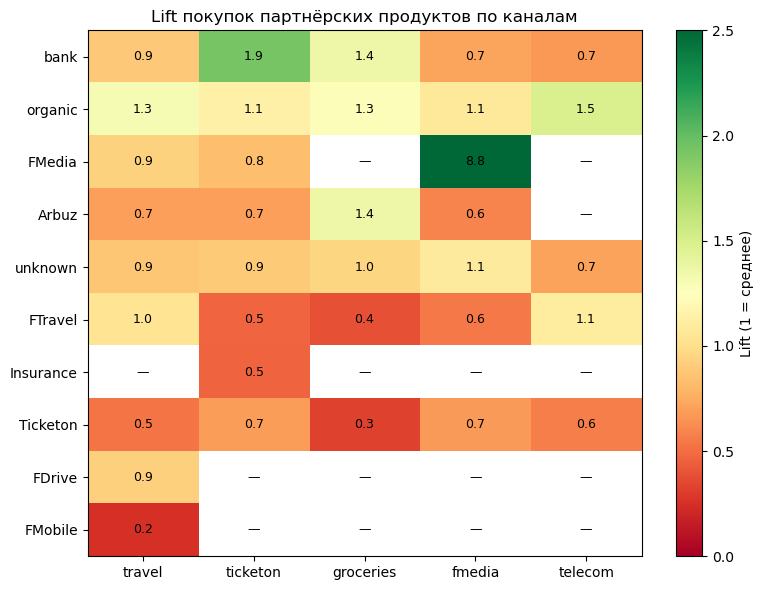

In [18]:
masked = lift_map.where(buyers >= 30)
fig, ax = plt.subplots(figsize=(8, 6))
im = ax.imshow(masked.values, cmap="RdYlGn", vmin=0, vmax=2.5, aspect="auto")
ax.set_xticks(range(len(PROD_LIST)))
ax.set_xticklabels(PROD_LIST)
ax.set_yticks(range(len(masked.index)))
ax.set_yticklabels(masked.index)
for i in range(masked.shape[0]):
    for j in range(masked.shape[1]):
        v = masked.iloc[i, j]
        ax.text(j, i, "—" if pd.isna(v) else f"{v:.1f}", ha="center", va="center", fontsize=9)
plt.colorbar(im, label="Lift (1 = среднее)")
ax.set_title("Lift покупок партнёрских продуктов по каналам")
plt.tight_layout()
plt.show()

In [19]:
OWN = {"Ticketon": "ticketon", "FTravel": "travel", "Arbuz": "groceries",
       "FMedia": "fmedia", "FMobile": "telecom"}   # допущение по названиям

rows = []
for ch in lift_map.index:
    for p in PROD_LIST:
        if OWN.get(ch) == p or buyers.loc[ch, p] < 30:
            continue
        rows.append({"Канал": ch, "Продукт": p, "Клиентов канала": int(res.loc[ch, "Клиентов"]),
                     "Покупателей": int(buyers.loc[ch, p]), "Доля": rates.loc[ch, p],
                     "Lift": lift_map.loc[ch, p]})
pairs_rank = pd.DataFrame(rows).sort_values("Lift", ascending=False)
print("Самые сильные неочевидные связки (канал → продукт), покупателей не меньше 30:")
display(pairs_rank.head(8).round(3).reset_index(drop=True))
print("Самые слабые связки:")
display(pairs_rank.tail(5).round(3).reset_index(drop=True))

Самые сильные неочевидные связки (канал → продукт), покупателей не меньше 30:


,Канал,Продукт,Клиентов канала,Покупателей,Доля,Lift
0,bank,ticketon,16802,1900,0.113,1.932
1,organic,telecom,80975,556,0.007,1.491
2,bank,groceries,16802,386,0.023,1.358
3,organic,travel,80975,6079,0.075,1.303
4,organic,groceries,80975,1749,0.022,1.277
5,organic,ticketon,80975,5372,0.066,1.134
6,FTravel,telecom,14057,71,0.005,1.097
7,unknown,fmedia,57821,830,0.014,1.091


Самые слабые связки:


,Канал,Продукт,Клиентов канала,Покупателей,Доля,Lift
0,FTravel,ticketon,14057,388,0.028,0.472
1,Insurance,ticketon,1391,38,0.027,0.467
2,FTravel,groceries,14057,92,0.007,0.387
3,Ticketon,groceries,22456,124,0.006,0.326
4,FMobile,travel,2272,32,0.014,0.244



## 10. Выводы (заполни своими словами по результатам)

1. **Данные:** клиентов с несколькими каналами ...%, поэтому ... Пустой канал (`unknown`) у ...%. У ...% клиентов с известной датой регистрации есть операции раньше регистрации (признак склейки id).
2. **Качество каналов:** лучшие по активации и активности за 30 дней ... (активация ...%, активны за 30 дней ...%). Крупные каналы с качеством ниже среднего: ...
3. **Устойчивость:** ранжирование при смене правила атрибуции ... (корреляция рангов ...), поправка на месяц регистрации ...
4. **Время до первой операции:** в течение 7 дней первую операцию делают ...% клиентов канала ..., ...% канала ... Разные каналы отличаются по скорости ...
5. **Точка застревания:** у канала ... главная потеря на шаге «...», у канала ... на шаге «...». «Застрявших» (карта есть, операций нет) всего ...; больше всего в каналах ...
6. **Кросс-продажи:** самые сильные неочевидные связки: ... (lift ...). Самые слабые: ...
7. **Рекомендации:** (а) кампания активации для «застрявших» с бонусом за первую операцию, начиная с каналов ...; (б) продуктовые предложения по связкам ...; (в) пересмотреть бюджет на каналы с низким качеством ...; всё проверить A/B-тестом с контрольной группой.
8. **Ограничения:** нет стоимости привлечения и даты касаний; у части клиентов несколько каналов; дата регистрации взята по самой ранней записи (id в пользователях не уникален); шаги воронки по процессам не привязаны к окну 30 дней; соответствие каналов продуктам это допущение по названиям; канал может отражать тип клиента, а не эффект самого канала.
